# 📤 Import & Install Libraries

In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 💾 Prepare the Data

In [123]:
df = pd.read_csv(r"data\apartments.csv") #Loading the dataset via pandas module
area = df[["area_m2"]].values
price = df.price_thousands_pln.values

In [124]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   area_m2              10 non-null     int64
 1   price_thousands_pln  10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


In [125]:
print(df.head(5)) #First 5 rows from the dataset

   area_m2  price_thousands_pln
0       35                  310
1       42                  355
2       50                  395
3       57                  430
4       65                  470


In [126]:
df.describe() #Basic descriptive statistics about the data

,area_m2,price_thousands_pln
count,10.000000,10.000000
mean,71.100000,509.000000
std,26.863647,146.055545
min,35.000000,310.000000
25%,51.750000,403.750000
50%,68.500000,492.500000
75%,87.500000,601.250000
max,120.000000,770.000000


In [127]:
df.corr()

,area_m2,price_thousands_pln
area_m2,1.000000,0.999681
price_thousands_pln,0.999681,1.000000


<Axes: >

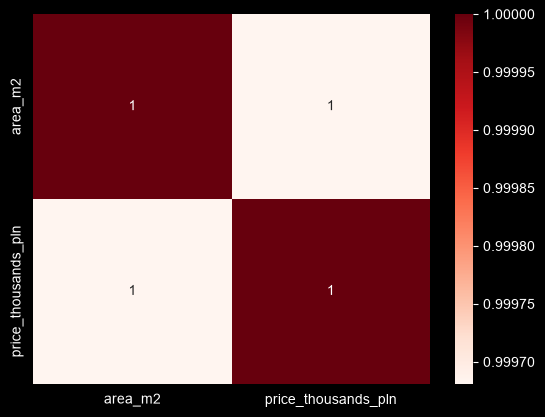

In [128]:
sns.heatmap(df.corr(), annot=True, cmap="Reds")  #If area increases price does increase as well

# What problem are trying to solve?

We are trying to predict price (thousands of PLN) from floor area by using simple linear regression algorithm.

# Exploratory Data Analysis

As seen from the data, area and price has positive relationship, hence, makes the slop positive

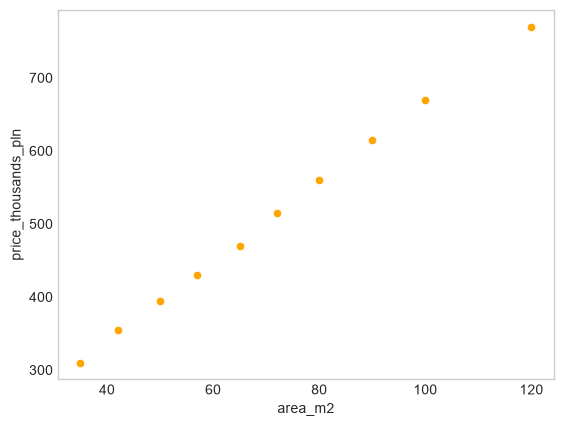

In [160]:
sns.scatterplot(data=df, x="area_m2", y="price_thousands_pln", color="orange") #Dependent price according to independent area
plt.grid()
plt.show()

In [130]:
model = LinearRegression()
model.fit(area, price)
print("Coefficient b1:", model.coef_[0])
print("Intercept b0:", model.intercept_)

Coefficient b1: 5.435187608739161
Intercept b0: 122.55816101864565



**Linear Regression Formula:**
x is area, b1 is Coefficient (slope), b0 is intercept, y is the price
            $$\hat{y} = b_0 + b_1 x$$

In [131]:
sample = np.array([[40],[60],[80],[100]])   #2D array with shape (4,1)
pred = model.predict(sample)

for m2, p in zip(sample.flatten(), pred): #Flattens the multidimensional array into one-dimensional array to match sample with prediction
    print(f"Predicted price for {m2} m²: {p:.1f} thousand PLN")


Predicted price for 40 m²: 340.0 thousand PLN
Predicted price for 60 m²: 448.7 thousand PLN
Predicted price for 80 m²: 557.4 thousand PLN
Predicted price for 100 m²: 666.1 thousand PLN


#   ✔️Goodness-of-Fit (The higher the better)
*   R2 tells us how well a regression line predicts the actual values. It is calculated via comparing the actual values "price" to estimated values "model.predict(area)"     $$R^2 = \frac{SS_{reg}}{SS_{tot}} = \frac{\sum_{i=1}^{n}(\hat{y}_i - \bar{y})^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

In [137]:
price_predict = model.predict(area)
r2 = r2_score(price,price_predict)
print(f"R2 value is: {r2}")

R2 value is: 0.9993622468675517


#   ✔Error Metrics (The lower the better)

*   Standard Error Estimate calculates how good our estimation fits. Found via comparison in between the actual values to estimated values.
                            $$s_e = \sqrt{\frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{n-k-1}}$$

*   **MAE** (mean absolute error)

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|y_i - \hat{y}_i\right|$$

* **MSE** (mean squared error)

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

* **RMSE** (root mean squared error)

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

In [136]:
MAE = mean_absolute_error(price,price_predict)
MSE = mean_squared_error(price,price_predict)
RMSE = np.sqrt(MSE)
print(f"Mean absolute error is {MAE}")
print(f"Mean squared error is {MSE}")
print(f"Root mean squared error is {RMSE}")

Mean absolute error is 3.155922339066035
Mean squared error is 12.244222389875123
Root mean squared error is 3.499174529782006


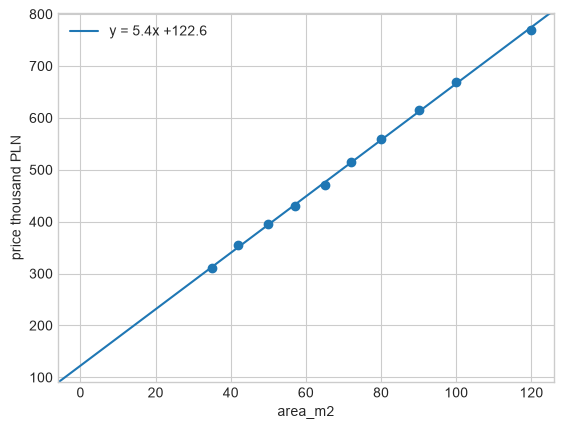

In [176]:

plt.scatter(area,price)
plt.axline(xy1=(0, model.intercept_), slope=model.coef_[0], label=f'y = {model.coef_[0]:.1f}x +{model.intercept_:.1f}' )
plt.xlabel("area_m2")
plt.ylabel("price thousand PLN")
plt.legend()
plt.savefig("regression.png")
plt.show()